### 태풍 찬투(CHANTHU, 2021년 14호) - 경로 지도와 강도 변화 분석
### 학습 내용
 * 기본 분석([01_05_Typhoon_analysis](https://ldjwj.github.io/dataAnalysis/01_05_Typhoon_analysis.html))에서 하지 못한 **위치(위도·경도)와 시간 정보**를 활용하기
 * **folium**으로 태풍 경로 지도를 그리고, 시간에 따른 중심기압·최대풍속·이동속도 변화를 시각화
 * 데이터가 51행뿐일 때 **모델 점수가 얼마나 불안정한지** 확인하고, 시간 순서를 이용한 간단한 기준(baseline) 알아보기

### 내용
 * 0. 기본 분석 돌아보기 - 무엇을 보완할까?
 * 1. 데이터 준비 (2줄 헤더 처리, 날짜 변환)
 * 2. 태풍 경로 지도 (folium)
 * 3. 시간에 따른 중심기압 · 최대풍속 · 이동속도 변화
 * 4. 중심기압과 최대풍속의 관계
 * 5. 이동속도 예측 결과 돌아보기
 * 6. 한반도 영향 - 지점별 순간풍속 · 강수량 (CALP 파일)
 * 7. 정리

### 0. 기본 분석 돌아보기 - 무엇을 보완할까?
 * **사용하지 않은 정보** : 기본 분석은 `중심기압, 최대풍속, 강풍반경, 폭풍반경` 4개 변수만 사용했다.
   * `위도, 경도`(태풍의 위치)와 `일시`(시간)는 사용하지 않았다. 태풍 데이터의 핵심은 **어디로, 어떻게 움직였는가**이다.
   * 위도·경도 컬럼이 문자(object)로 남아 있었다(2줄 헤더 때문에 첫 행에 '위도(˚N)' 글자가 섞임).
 * **이동속도 예측 결과** (train 40개 / test 11개, `random_state=0`)
   * 테스트 R² : 선형회귀 **-0.01**, KNN **0.16**, 랜덤포레스트 **-0.03** → 평균값으로 찍는 것보다 나을 게 없는 수준
   * 결론은 "데이터가 너무 작다"였다. 이번에는 **왜 그런지**를 데이터의 흐름(시간 순서)에서 살펴본다.
 * **사용하지 않은 파일** : `..._CALP.xls`(한반도 지점별 일 최대순간풍속·일강수량 순위)
   * `data/Typhoon/20220514120837.zip` 및 폴더 안의 zip을 풀어 보면 같은 이름의 xls 2개가 들어 있고, **시트 내용은 위 두 파일과 동일**하다. 따라서 이번 분석은 두 xls 파일을 사용한다.

### 필수 라이브러리 불러오기

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import folium
import warnings
warnings.filterwarnings('ignore')

# 한글 폰트 설정
# - koreanize-matplotlib이 설치되어 있으면 OS와 상관없이 나눔고딕을 사용 (pip install koreanize-matplotlib)
# - 없으면 OS에 맞는 기본 한글 폰트를 사용
try:
    import koreanize_matplotlib
except ImportError:
    import platform
    plt.rcParams['font.family'] = {'Windows': 'Malgun Gothic',
                                   'Darwin': 'AppleGothic'}.get(platform.system(), 'NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

sns.set_theme(style='whitegrid', font=plt.rcParams['font.family'])

### 1. 데이터 준비
 * 엑셀의 1~2행이 **2줄 헤더**(중심위치 → 위도/경도)이므로 `skiprows=2`로 건너뛰고 컬럼 이름을 직접 지정한다.
 * 이렇게 하면 위도·경도가 처음부터 숫자로 읽힌다.

In [2]:
file_path = "./data/Typhoon/ISSUE_TY_2021_14_CHANTHU_20210907_2021.xls"
df = pd.read_excel(file_path, header=None, skiprows=2)
df.columns = ['구분', '일시', '위도', '경도', '중심기압', '최대풍속',
              '강풍반경', '폭풍반경', '강도', '진행방향', '이동속도']

# '2021년 09월 07일 09시' → 날짜 형식
df['일시'] = pd.to_datetime(df['일시'], format='%Y년 %m월 %d일 %H시')
print(df.shape)
df.dtypes

(51, 11)


구분                 str
일시      datetime64[us]
위도             float64
경도             float64
중심기압             int64
최대풍속             int64
강풍반경             int64
폭풍반경             int64
강도                 str
진행방향               str
이동속도             int64
dtype: object

* 한줄 확인 : 51개 관측 시점, 위도·경도·기압·풍속 모두 숫자형으로 읽혔다. (단위: 기압 hPa, 풍속 m/s, 반경 km, 이동속도 km/h)

In [3]:
# 관측 간격 확인 - 언제부터 간격이 바뀌는지
df['간격(시간)'] = df['일시'].diff().dt.total_seconds() / 3600
print(df['간격(시간)'].value_counts())
print('처음 :', df['일시'].min(), '/ 마지막 :', df['일시'].max())
df.loc[df['간격(시간)'] == 3, '일시'].min()

간격(시간)
6.0    38
3.0    12
Name: count, dtype: int64
처음 : 2021-09-07 09:00:00 / 마지막 : 2021-09-18 09:00:00


Timestamp('2021-09-16 12:00:00')

* 한줄 확인 : 처음에는 **6시간 간격**(38번)이다가 한반도에 가까워진 **9월 16일 12시부터 3시간 간격**(12번)으로 촘촘해진다. 9월 7일 09시 ~ 9월 18일 09시, 총 **11일간**의 기록

In [4]:
# 강도 / 구분 값의 분포
print(df['구분'].value_counts().to_string(), end='\n\n')
print(df['강도'].value_counts().to_string())

구분
TY     28
STS    17
TS      5
LOW     1

강도
중       17
매우 강    16
강       10
-        6
초강력      2


* 한줄 확인 : `구분`은 국제 분류(TS 열대폭풍 → STS 강한 열대폭풍 → TY 태풍 → LOW 저기압), `강도`는 기상청 분류(`-` → 중 → 강 → 매우 강 → 초강력)이다.
   * '매우 강' 16회, '초강력'도 2회 기록된 강한 태풍이었다.

In [5]:
# 강도 순서와 색 지정 (약 → 강)
level_order = ['-', '중', '강', '매우 강', '초강력']
level_color = {'-': '#4C9BE8', '중': '#F2C230', '강': '#F28C28', '매우 강': '#D7301F', '초강력': '#7A0177'}
df['강도'] = pd.Categorical(df['강도'], categories=level_order, ordered=True)

# 가장 강했던 시점
df.loc[[df['중심기압'].idxmin()], ['일시', '위도', '경도', '중심기압', '최대풍속', '강도']]

,일시,위도,경도,중심기압,최대풍속,강도
9,2021-09-09 15:00:00,15.8,127.1,915,55,초강력


* 한줄 확인 : **9월 9일 15시**(필리핀 동쪽 바다, 북위 15.8° 동경 127.1°)에 중심기압 **915hPa**, 최대풍속 **55m/s**로 가장 강했다(초강력).

### 2. 태풍 경로 지도 (folium)
 * 관측 지점마다 원 마커를 찍고, **강도에 따라 색**을 다르게 한다(원의 크기 = 최대풍속).
 * 시간 순으로 이웃한 두 지점을 선으로 이어 경로를 표시한다. 마커를 클릭하면 시각·기압·풍속을 볼 수 있다.

In [6]:
m = folium.Map(location=[26, 128], zoom_start=4, tiles='cartodbpositron')

# 1) 경로선 - 구간마다 출발 지점의 강도 색으로
for i in range(len(df) - 1):
    a, b = df.iloc[i], df.iloc[i + 1]
    folium.PolyLine([[a['위도'], a['경도']], [b['위도'], b['경도']]],
                    color=level_color[a['강도']], weight=4, opacity=0.8).add_to(m)

# 2) 관측 지점 마커
for _, r in df.iterrows():
    info = (f"<b>{r['일시']:%m/%d %H시}</b><br>구분: {r['구분']} / 강도: {r['강도']}<br>"
            f"중심기압: {r['중심기압']} hPa<br>최대풍속: {r['최대풍속']} m/s<br>"
            f"이동: {r['진행방향']} {r['이동속도']} km/h")
    folium.CircleMarker([r['위도'], r['경도']], radius=r['최대풍속'] / 6,
                        color=level_color[r['강도']], fill=True, fill_opacity=0.8,
                        popup=folium.Popup(info, max_width=220),
                        tooltip=f"{r['일시']:%m/%d %H시} {r['강도']}").add_to(m)

# 3) 시작 / 최강 / 마지막 지점 표시
for idx, label in [(0, '발생 09/07'), (df['중심기압'].idxmin(), '최강 915hPa'), (len(df) - 1, '소멸 09/18')]:
    r = df.loc[idx]
    folium.Marker([r['위도'], r['경도']], tooltip=label,
                  icon=folium.Icon(color='gray', icon='info-sign')).add_to(m)

# 4) 범례
legend = '<div style="position:fixed; bottom:20px; left:20px; z-index:9999; background:white; padding:8px; border:1px solid #999; font-size:13px">'
legend += '<b>강도</b><br>' + ''.join(
    f'<span style="color:{c}">&#9679;</span> {k if k != "-" else "약(-)"}<br>' for k, c in level_color.items()) + '</div>'
m.get_root().html.add_child(folium.Element(legend))
m

* 한줄 확인 : 필리핀 동쪽에서 **서쪽으로** 이동하며 '매우 강~초강력'으로 발달 → 대만 동쪽에서 **북쪽으로 방향을 틀고** → 중국 상하이 앞바다(북위 30~31°)에서 **며칠간 맴돈 뒤** → 제주 남쪽을 지나 **동북동으로 빠르게** 일본 쪽으로 빠져나갔다.

In [7]:
# 구간 거리 계산 (하버사인 공식, 지구 반지름 6371km)
lat, lon = np.radians(df['위도']), np.radians(df['경도'])
dlat, dlon = lat.diff(), lon.diff()
h = np.sin(dlat / 2)**2 + np.cos(lat) * np.cos(lat.shift()) * np.sin(dlon / 2)**2
df['구간거리(km)'] = 2 * 6371 * np.arcsin(np.sqrt(h))
df['계산속도(km/h)'] = df['구간거리(km)'] / df['간격(시간)']

print(f"총 이동 거리 : {df['구간거리(km)'].sum():,.0f} km")
print(f"기록된 이동속도와 계산 속도의 상관계수 : {df['이동속도'].corr(df['계산속도(km/h)']):.3f}")
print(f"두 속도 차이(절대값) 평균 : {(df['이동속도'] - df['계산속도(km/h)']).abs().mean():.1f} km/h")

총 이동 거리 : 4,748 km
기록된 이동속도와 계산 속도의 상관계수 : 0.953
두 속도 차이(절대값) 평균 : 2.1 km/h


* 한줄 확인 : 11일 동안 약 **4,748km**를 이동했다. 위치 변화로 직접 계산한 속도와 기록된 `이동속도`의 상관계수는 **0.953**(평균 차이 2.1km/h)으로, 이동속도는 **직전 관측 이후 위치 변화**를 거의 그대로 나타낸 값임을 알 수 있다.

### 3. 시간에 따른 중심기압 · 최대풍속 · 이동속도 변화
 * 세 그래프의 x축(시간)을 공유하고, 배경색으로 강도 구간을 표시한다.

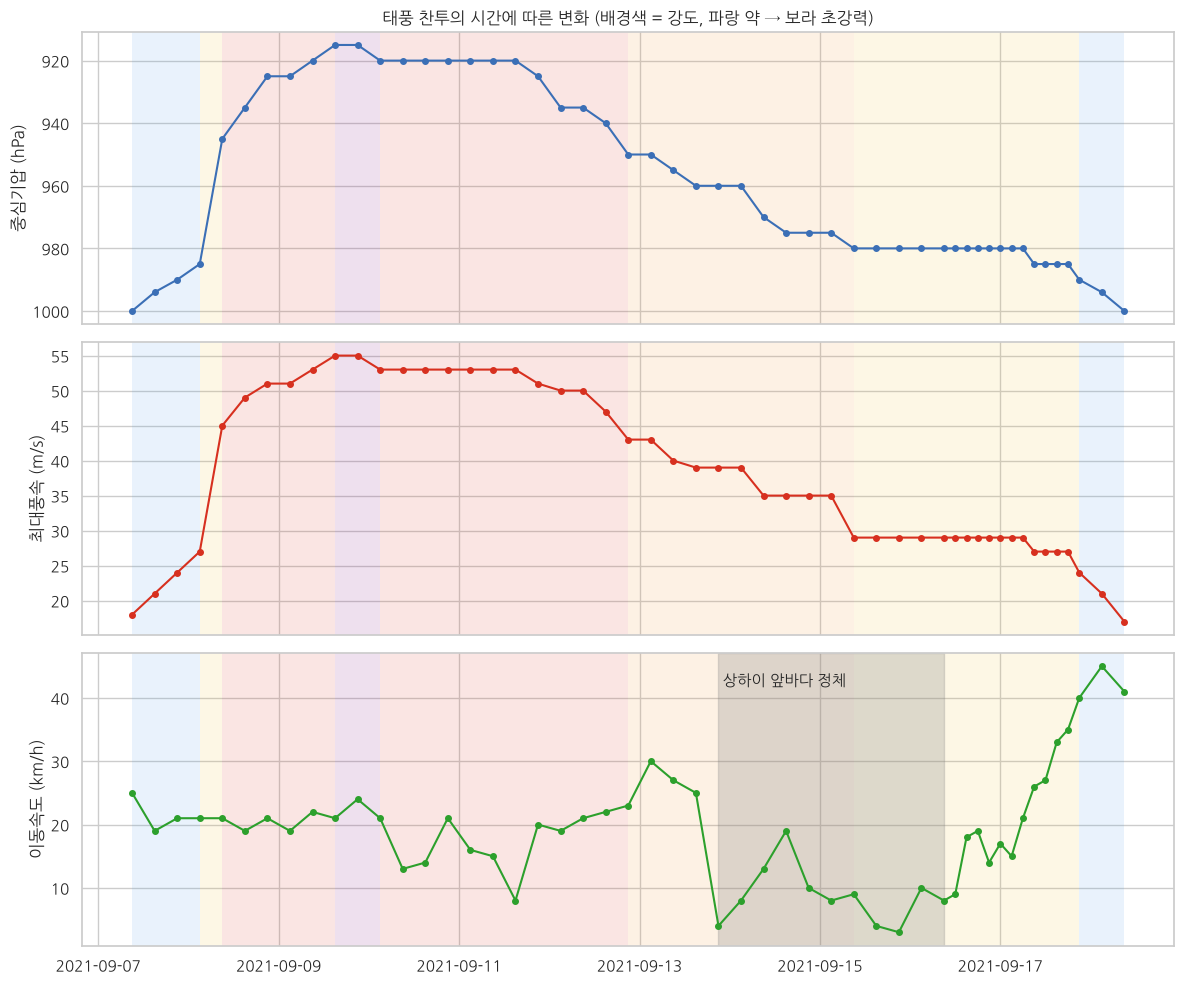

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
items = [('중심기압', 'hPa', '#3B6FB6'), ('최대풍속', 'm/s', '#D7301F'), ('이동속도', 'km/h', '#2CA02C')]

for ax, (col, unit, c) in zip(axes, items):
    ax.plot(df['일시'], df[col], marker='o', ms=4, color=c)
    ax.set_ylabel(f'{col} ({unit})')
    # 강도별 배경색
    for i in range(len(df) - 1):
        ax.axvspan(df['일시'].iloc[i], df['일시'].iloc[i + 1],
                   color=level_color[df['강도'].iloc[i]], alpha=0.12, lw=0)

axes[0].invert_yaxis()   # 기압은 낮을수록 강하므로 위아래 뒤집기
axes[0].set_title('태풍 찬투의 시간에 따른 변화 (배경색 = 강도, 파랑 약 → 보라 초강력)')

# 정체 구간 표시 (상하이 앞바다에서 이동속도가 크게 느려진 기간)
stall = df[(df['일시'] >= '2021-09-13 21:00') & (df['일시'] <= '2021-09-16 09:00')]
axes[2].axvspan(stall['일시'].min(), stall['일시'].max(), color='gray', alpha=0.25)
axes[2].text(stall['일시'].min(), 42, ' 상하이 앞바다 정체', fontsize=11)
plt.tight_layout()
plt.show()

In [9]:
# 시기별 평균 비교
df['시기'] = np.select(
    [df['일시'] < '2021-09-13 21:00', df['일시'] <= '2021-09-16 09:00'],
    ['① 발달·북상 (09/07~09/13)', '② 정체 (09/13 21시~09/16 09시)'], '③ 가속·소멸 (09/16 12시~)')
df.groupby('시기')[['중심기압', '최대풍속', '이동속도']].agg(['mean', 'min', 'max']).round(1)

중심기압             최대풍속          이동속도        
                             mean  min   max  mean min max  mean min max
시기                                                                      
① 발달·북상 (09/07~09/13)       940.0  915  1000  45.5  18  55  20.3   8  30
② 정체 (09/13 21시~09/16 09시)  974.1  960   980  33.0  29  39   8.7   3  19
③ 가속·소멸 (09/16 12시~)        984.6  980  1000  26.6  17  29  25.7   9  45

* 한줄 확인 : 발생 후 **약 2일 만에** 1000hPa → 915hPa로 급격히 발달했고, 이후 기압이 서서히 올라가며(약해지며) 북상했다.
   * **② 정체기**(약 2.5일)에는 이동속도가 평균 **8.7km/h**(최저 3km/h)로 거의 멈춰 있었다. (발달·북상기 평균 20.3km/h)
   * **③ 가속기**에는 평균 **25.7km/h**, 최고 **45km/h**로 빨라졌다. 편서풍대에 들어가 빠르게 빠져나가는 전형적인 모습이다.
   * 기압·풍속은 단계적으로 약해지지만, 이동속도는 시기에 따라 크게 달라진다 → 이동속도는 태풍 자체의 세기와는 **다른 요인**(주변 바람)의 영향을 받는다.

### 4. 중심기압과 최대풍속의 관계

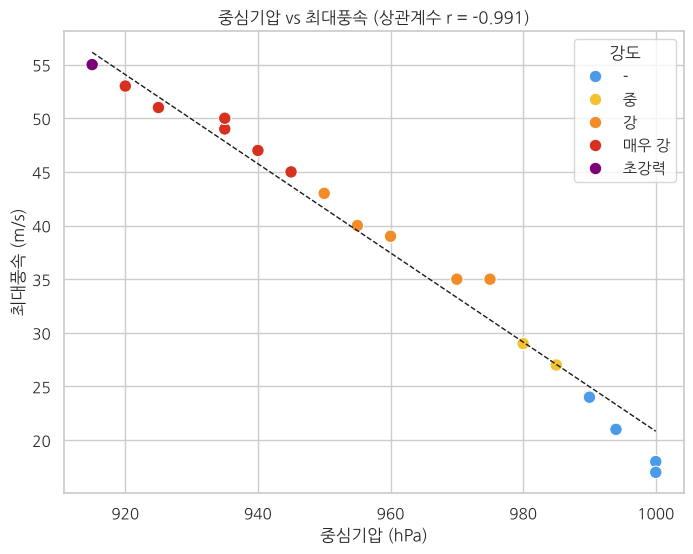

기울기 : -0.415 m/s per hPa, 결정계수 R² : 0.982


In [10]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression().fit(df[['중심기압']], df['최대풍속'])
r = df['중심기압'].corr(df['최대풍속'])

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df, x='중심기압', y='최대풍속', hue='강도', palette=level_color,
                s=80, ax=ax)
xs = np.linspace(df['중심기압'].min(), df['중심기압'].max(), 50)
ax.plot(xs, lr.predict(pd.DataFrame({'중심기압': xs})), 'k--', lw=1)
ax.set_title(f'중심기압 vs 최대풍속 (상관계수 r = {r:.3f})')
ax.set_xlabel('중심기압 (hPa)'); ax.set_ylabel('최대풍속 (m/s)')
plt.show()

print(f'기울기 : {lr.coef_[0]:.3f} m/s per hPa, 결정계수 R² : {lr.score(df[["중심기압"]], df["최대풍속"]):.3f}')

* 한줄 확인 : 상관계수 **-0.991**, 거의 한 직선 위에 있다. 중심기압이 **10hPa 낮아질 때 최대풍속이 약 4.2m/s 강해진다**.
   * 강도(색) 역시 기압·풍속 구간에 따라 정해지므로 오른쪽 아래(약) → 왼쪽 위(초강력) 순으로 정렬되어 있다.
   * 따라서 기본 분석에서 두 변수를 함께 넣은 것은 **사실상 같은 정보를 두 번 넣은 것**(다중공선성)이다.

### 5. 이동속도 예측 결과 돌아보기
#### 5-1. 테스트 점수는 데이터를 어떻게 나누느냐에 따라 크게 달라진다
 * 기본 분석과 같은 변수·모델로, 데이터 분할(`random_state`)만 0~29로 바꾸며 30번 반복한다.

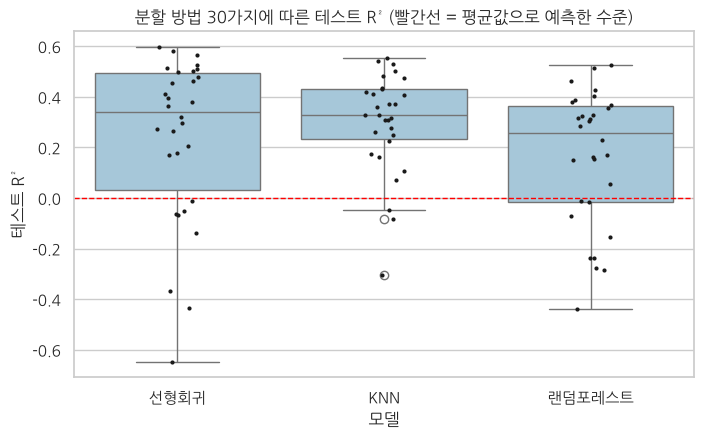

,mean,min,50%,max
모델,,,,
KNN,0.30,-0.31,0.33,0.55
랜덤포레스트,0.16,-0.44,0.26,0.53
선형회귀,0.24,-0.65,0.34,0.60


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

sel = ['중심기압', '최대풍속', '강풍반경', '폭풍반경']
X, y = df[sel], df['이동속도']

models = {'선형회귀': LinearRegression(),
          'KNN': KNeighborsRegressor(),
          '랜덤포레스트': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=2)}
rows = []
for seed in range(30):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
    for name, model in models.items():
        rows.append({'seed': seed, '모델': name, '테스트 R²': model.fit(X_tr, y_tr).score(X_te, y_te)})
scores = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=scores, x='모델', y='테스트 R²', ax=ax, color='#9ecae1')
sns.stripplot(data=scores, x='모델', y='테스트 R²', ax=ax, color='k', size=3)
ax.axhline(0, color='red', ls='--', lw=1)
ax.set_title('분할 방법 30가지에 따른 테스트 R² (빨간선 = 평균값으로 예측한 수준)')
plt.show()

scores.groupby('모델')['테스트 R²'].describe()[['mean', 'min', '50%', 'max']].round(2)

* 한줄 확인 : 같은 모델이라도 분할에 따라 테스트 R²가 크게 흔들린다(선형회귀 **-0.65 ~ 0.60**, KNN **-0.31 ~ 0.55**, 랜덤포레스트 **-0.44 ~ 0.53**).
   * 테스트 데이터가 11개뿐이라 **어떤 11개가 뽑히느냐**가 점수를 좌우한다. 기본 분석의 결과(-0.01 등)는 그중 운이 나쁜 한 번이었다.
   * 하나의 점수만 보고 판단하지 말고, 여러 번 나누어 보는 **교차 검증**이 필요하다.

#### 5-2. 이동속도와 다른 변수의 상관관계

In [12]:
df[['중심기압', '최대풍속', '강풍반경', '폭풍반경', '위도', '경도', '이동속도']].corr()['이동속도'].drop('이동속도').round(3).sort_values()

강풍반경   -0.601
폭풍반경   -0.485
최대풍속   -0.201
위도      0.080
중심기압    0.157
경도      0.503
Name: 이동속도, dtype: float64

* 한줄 확인 : 기압(0.157)·풍속(-0.201)과 이동속도의 상관은 약하다. 강풍반경(-0.601), 경도(0.503)가 상대적으로 크지만,
   * 강풍반경은 태풍 후반에 280km로 일정하게 유지되던 시기(정체기 포함)와 겹쳐서 생긴 관계이고,
   * 경도는 마지막에 동쪽(일본)으로 빠르게 빠져나간 구간의 영향이다. 즉, 이동속도는 **태풍의 세기보다 위치·시기(주변 기압계)** 와 관련이 크다.

#### 5-3. 시간 순서를 이용한 간단한 기준 - "직전 속도로 다음 속도 맞히기"
 * 태풍 데이터는 **시간 순서가 있는 데이터(시계열)** 이다. 가장 단순한 예측은 "다음 이동속도 = 지금 이동속도"(지속성 예측)

In [13]:
y = df['이동속도']
mae_mean = (y - y.mean()).abs().mean()           # 전체 평균값으로 예측
mae_persist = (y - y.shift(1)).abs().mean()      # 직전 값으로 예측 (첫 행 제외)
print(f'평균값으로 예측할 때 MAE : {mae_mean:.1f} km/h')
print(f'직전 값으로 예측할 때 MAE : {mae_persist:.1f} km/h')

평균값으로 예측할 때 MAE : 6.7 km/h
직전 값으로 예측할 때 MAE : 4.0 km/h


* 한줄 확인 : 직전 속도를 그대로 쓰기만 해도 오차(MAE)가 **6.7 → 4.0km/h**로 줄어든다.
   * 기본 분석처럼 시점을 무작위로 섞으면 이런 **시간의 흐름 정보가 사라진다**. 시계열 데이터는 직전 값(lag), 위도·경도 변화 등을 특성으로 만들고 **시간 순서대로** 학습/검증을 나누는 것이 자연스럽다.

### 6. 한반도 영향 - 지점별 순간풍속 · 강수량 (CALP 파일)
 * `_CALP.xls` : 기상청 관측 지점 중 날짜별 **일 최대순간풍속 / 일강수량 상위 10개 지점**, 그리고 전체 기간 **누적강수량 상위 10개 지점**
 * 한 행에 날짜마다 (순위, 지점, 값) 3칸씩 옆으로 이어 붙은 구조이므로, 3칸씩 잘라서 세로(긴 형태)로 다시 쌓는다.

In [14]:
raw = pd.read_excel("./data/Typhoon/ISSUE_TY_2021_14_CHANTHU_20210907_2021_CALP.xls", header=None)
raw.iloc[:4, :7]

,0,1,2,3,4,5,6
0,일최대순간풍속(m/s),NaN,NaN,NaN,NaN,NaN,NaN
1,20210907,NaN,NaN,20210908,NaN,NaN,20210909
2,순위,지점,값,순위,지점,값,순위
3,1,북격렬비도,22.3,1,가거도,16.6,1


In [15]:
# 0행: 항목명(병합 셀이라 첫 칸에만 값) → 앞의 값으로 채우기, 1행: 날짜
item = raw.iloc[0].ffill()
rows = []
for j in range(0, raw.shape[1], 3):
    block = raw.iloc[3:13, j:j + 3].dropna()
    block.columns = ['순위', '지점', '값']
    block['항목'], block['날짜'] = item[j], str(raw.iloc[1, j])
    rows.append(block)
calp = pd.concat(rows, ignore_index=True)
calp['값'] = calp['값'].astype(float)
print(calp['항목'].value_counts())
calp.head()

항목
일최대순간풍속(m/s)    120
일강수량(mm)        110
누적강수량(mm)        10
Name: count, dtype: int64


,순위,지점,값,항목,날짜
0,1,북격렬비도,22.3,일최대순간풍속(m/s),20210907
1,2,가거도,22.1,일최대순간풍속(m/s),20210907
2,3,고창,20.8,일최대순간풍속(m/s),20210907
3,4,광덕산,20.6,일최대순간풍속(m/s),20210907
4,5,설악산,20.4,일최대순간풍속(m/s),20210907


* 한줄 확인 : 일 최대순간풍속 120행(12일 × 10개 지점), 일강수량 110행(비가 온 지점이 10곳보다 적은 날이 있음), 누적강수량 10행으로 정리되었다.

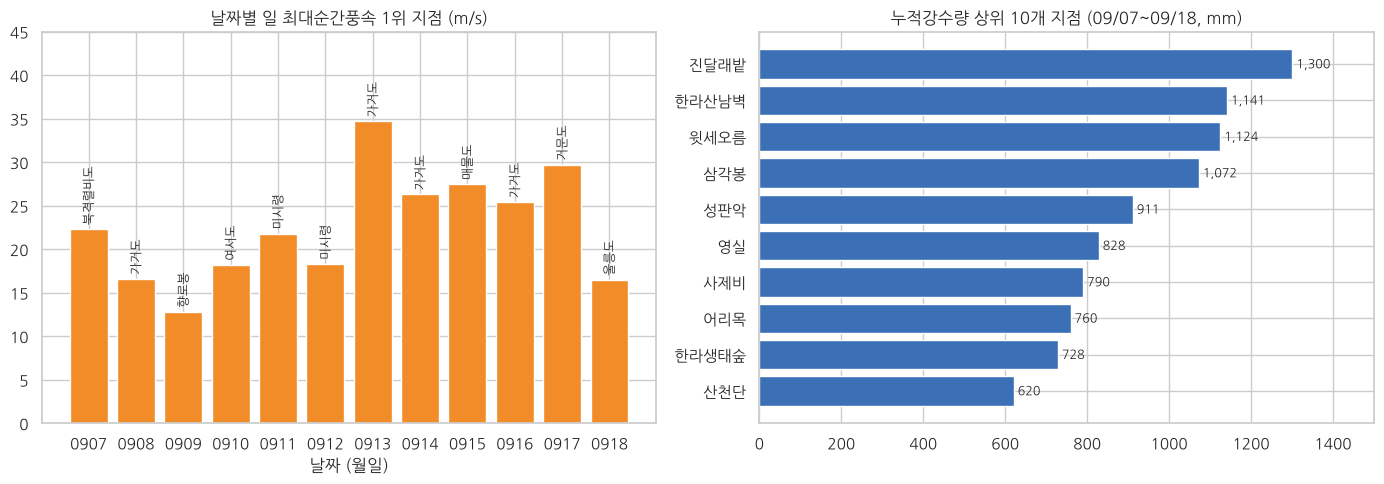

,0,10,20,30,40,50,60,70,80,90,100,110
날짜,20210907,20210908,20210909,20210910,20210911,20210912,20210913,20210914,20210915,20210916,20210917,20210918
지점,북격렬비도,가거도,향로봉,여서도,미시령,미시령,가거도,가거도,매물도,가거도,거문도,울릉도
값,22.3,16.6,12.8,18.2,21.8,18.3,34.7,26.3,27.5,25.4,29.7,16.5


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (1) 날짜별 1위 지점의 일 최대순간풍속
gust = calp[calp['항목'] == '일최대순간풍속(m/s)'].sort_values('값', ascending=False).drop_duplicates('날짜').sort_values('날짜')
bars = axes[0].bar(gust['날짜'].str[4:], gust['값'], color='#F28C28')
axes[0].bar_label(bars, labels=gust['지점'], fontsize=9, rotation=90, padding=3)
axes[0].set_ylim(0, 45)
axes[0].set_title('날짜별 일 최대순간풍속 1위 지점 (m/s)')
axes[0].set_xlabel('날짜 (월일)')

# (2) 기간 누적강수량 상위 10개 지점
rain = calp[calp['항목'] == '누적강수량(mm)'].sort_values('값')
axes[1].barh(rain['지점'], rain['값'], color='#3B6FB6')
for i, v in enumerate(rain['값']):
    axes[1].text(v + 10, i, f'{v:,.0f}', va='center', fontsize=9)
axes[1].set_xlim(0, 1500)
axes[1].set_title('누적강수량 상위 10개 지점 (09/07~09/18, mm)')
plt.tight_layout()
plt.show()

gust[['날짜', '지점', '값']].T

* 한줄 확인 : 순간풍속은 태풍이 동중국해를 북상하던 **9월 13일(가거도 34.7m/s)** 과 제주·남해안 부근을 지나간 **9월 17일(거문도 29.7m/s)** 에 가장 강했다.
   * 누적강수량 상위 10곳은 **모두 제주도 한라산 일대**(진달래밭 1,300mm, 한라산남벽 1,141mm 등) 관측소다. 태풍이 상하이 앞바다에서 며칠간 정체하는 동안 제주에 비가 계속 내린 결과로 볼 수 있다.

### 7. 정리
| 질문 | 기본 분석 | 추가 분석 결과 |
|---|---|---|
| 태풍은 어디로 움직였나? | 위도·경도 미사용 | 필리핀 동쪽 → 서진 → 대만 동쪽에서 북상 → 상하이 앞바다 정체 → 동북동으로 가속, 총 약 **4,748km** |
| 가장 강했던 때는? | - | **09/09 15시**, 중심기압 **915hPa**, 최대풍속 **55m/s**(초강력) |
| 이동속도는 어떻게 변했나? | 예측 대상으로만 사용 | 발달·북상기 평균 20.3km/h → 정체기 평균 **8.7km/h**(최저 3) → 가속기 평균 **25.7km/h**(최고 45) |
| 기압과 풍속의 관계는? | 둘 다 입력 변수로 사용 | 상관계수 **-0.991**, 10hPa 낮아질 때 풍속 약 4.2m/s 증가 → 거의 같은 정보 |
| 이동속도를 예측할 수 있나? | 테스트 R² -0.01 / 0.16 / -0.03 | 분할에 따라 R² **-0.65 ~ 0.60**으로 크게 흔들림. 직전 속도만 써도 MAE **6.7 → 4.0km/h** |
| 한반도 영향은? | CALP 파일 미사용 | 최대순간풍속 가거도 **34.7m/s**(09/13), 누적강수량 상위 10곳 모두 제주 한라산 (최대 **1,300mm**) |

#### 배운 점
 * 위도·경도·시간이 있는 데이터는 **지도와 시계열 그래프**로 먼저 보면 흐름(발달 → 정체 → 가속)이 한눈에 보인다.
 * 데이터가 적을 때 한 번의 train/test 분할 점수는 믿기 어렵다. **여러 번 나누어(교차 검증)** 분포로 확인하기
 * 시계열 데이터는 무작위로 섞기보다 **직전 값 같은 시간 정보**를 활용하는 것이 먼저다.

#### 다음에 해 볼 분석
 * 기상청에서 **여러 해의 태풍 데이터**를 모아 경로를 한 지도에 겹쳐 보고, 위도·직전 속도·진행방향을 특성으로 이동속도 예측(시간 순서 기반 검증)
 * CALP 지점명에 관측소 좌표(기상청 지점 정보)를 붙여 **강수량·풍속 지도** 만들기